# E2 · Transfer across body counts
*Step 1 of network-spectral-predictor · pendulums on springs · actual = generated world, nominal = prediction*

Fit on 3 and 5 pendulums; predict 8, wired four different ways, with no refit.

**Where we're at.** Step 1, rung 1. K and M decompose into body and spring (E1).

**Where the system is after the last experiments.** A fit on one small graph recovers ω₀² and κ to about 0.1%.

**Where we want it.** One fit that predicts any number of bodies, wired any way.

**How this set moves it.** Fits on 3- and 5-body paths and rings (random gates), then predicts 8-body paths, rings, stars and complete graphs without refitting, at three spring stiffnesses κ.

In [1]:
%config InlineBackend.figure_format = 'retina'
import sys
from pathlib import Path
import numpy as np
from IPython.display import display
STUDY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(STUDY))
import figures as F
from nsp import config, graphs, viz, world as W
F.setup()
cfg = F.cfg("e2")
world = config.world_from(cfg)
p = cfg["e2"]

In [2]:
F.ledger("e2")

**Configuration ledger**

| Setting | Value | Meaning |
| --- | --- | --- |
| `world.omega0` | 2.0 | a lone pendulum's frequency (rad/s) |
| `world.kappa` | 1.0 | spring stiffness ÷ inertia (1/s²) |
| `world.dt` | 0.05 | sampling step (s) |
| `world.d` | 1 | position coordinates per body (1 = planar) |
| `run.seeds` | [0, 1, 2] | seeds run (kept low on purpose) |
| `train_sizes` | [3, 5] | training body counts |
| `train_graphs` | ['path', 'ring'] | training graphs |
| `train_patterns` | 3 | random gate patterns per training graph |
| `train_trajectories` | 10 | trajectories per training configuration |
| `train_steps` | 200 | steps per training trajectory |
| `test_n` | 8 | test body count |
| `test_graphs` | ['path', 'ring', 'star', 'complete'] | test graphs |
| `test_trajectories` | 10 | trajectories per test |
| `test_steps` | 200 | steps per test rollout (200 = 10 s) |
| `kappas` | [1.0, 4.0, 16.0] | spring stiffnesses swept (1/s²) |
| `amplitude` | 0.1 | starting swing size (rad) |
| `horizons` | [10, 50, 200] | rollout horizons (steps) |
| `lambda_grid_max` | 9.0 | largest graph frequency plotted |

## The question

The assembled model splits into one $2\times 2$ problem per graph frequency:

$$\operatorname{spec}\big(I_n\otimes K - L(g)\otimes M\big) \;=\; \bigcup_k \operatorname{spec}\big(\underbrace{K - \lambda_k M}_{\text{mode } k}\big)$$

So the model only ever sees a graph through its frequencies $\lambda_k$, and transfer should follow $\lambda$, not the body count. What it misses is the two-hop term, of relative size

$$\frac{\text{two-hop}}{\text{one-hop}} \approx \frac{\kappa\lambda\Delta t^2}{6}$$

**Prediction.** Paths and rings of 8 ($\lambda\le 4$) sit at the edge of the training range ($\lambda\le 3.6$) and transfer; stars and complete graphs reach $\lambda = 8$ and come out several times worse, at every $\kappa$.
**Pass if** path-8 and ring-8 deviations at 10 s are within 1.5× of a model fitted on those graphs themselves.

In [3]:
runs = F.ensure_results("e2")

e2: 3 seeds loaded (code fb79448, run 2026-11-25T20:28:50+00:00)


## The worlds

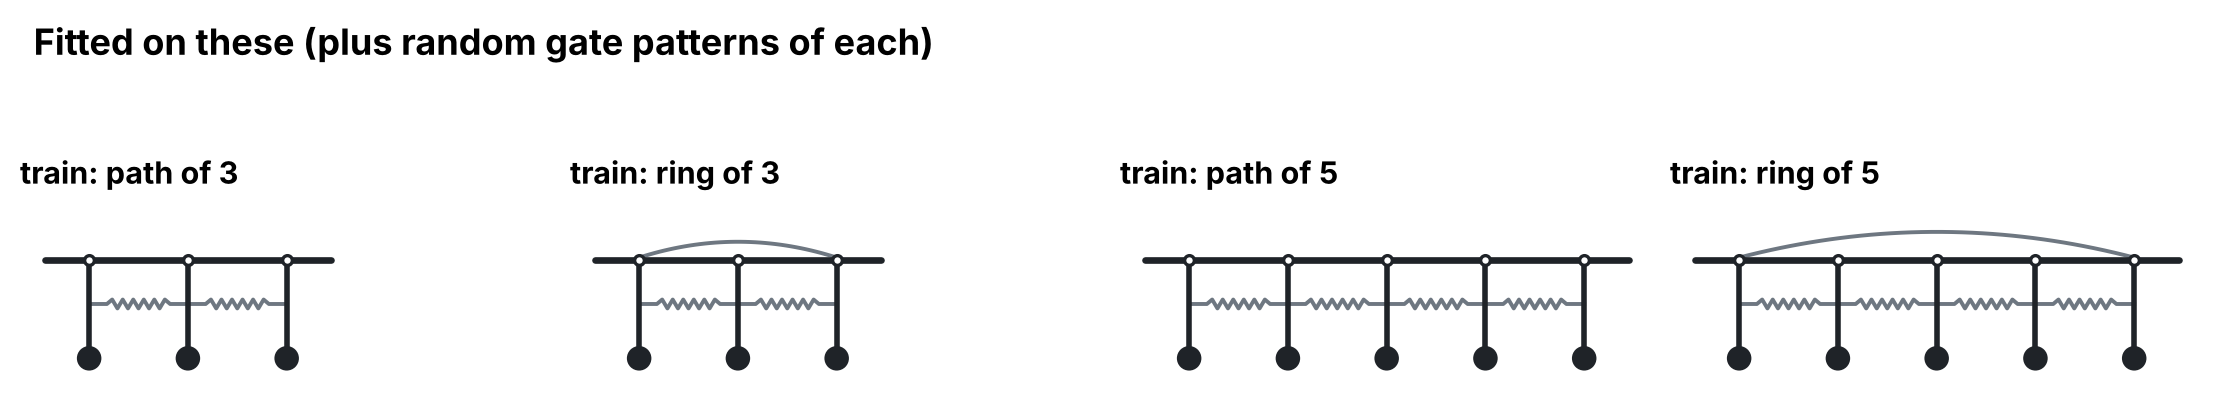

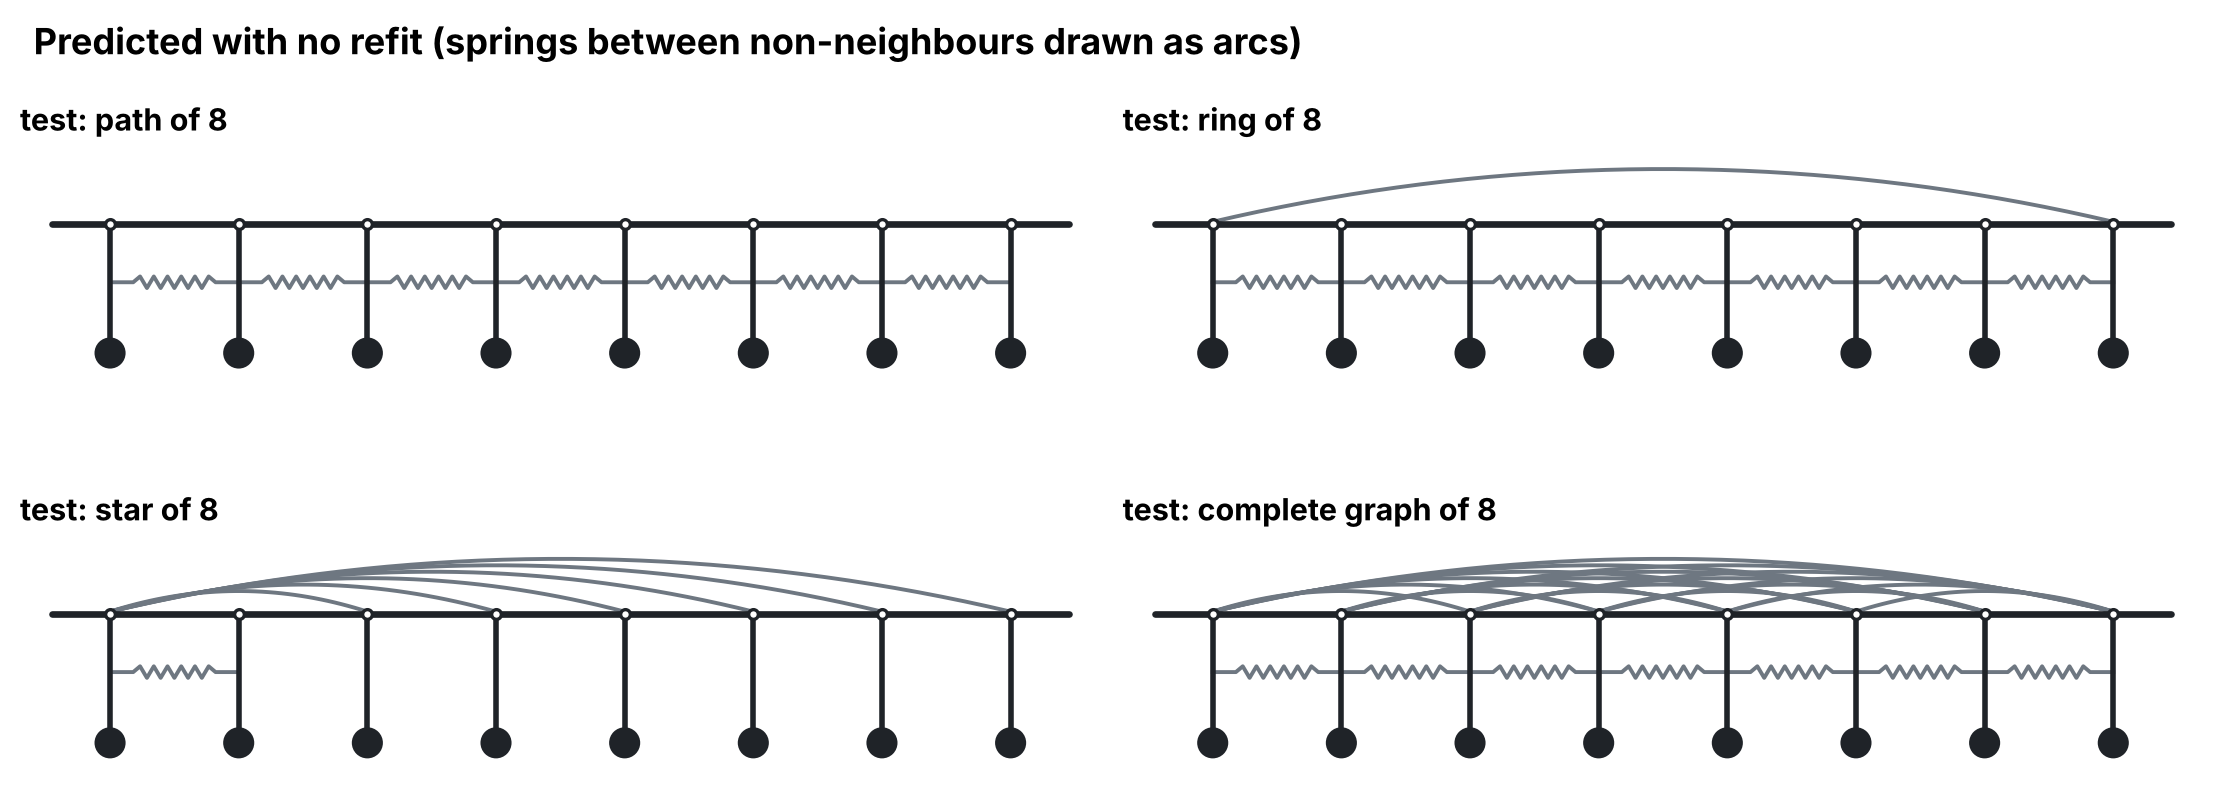

In [4]:
F.schematics([("train: path of 3", 3, graphs.path(3), None), ("train: ring of 3", 3, graphs.ring(3), None),
              ("train: path of 5", 5, graphs.path(5), None), ("train: ring of 5", 5, graphs.ring(5), None)],
             title="Fitted on these (plus random gate patterns of each)", cols=4);
F.schematics([("test: path of 8", 8, graphs.path(8), None), ("test: ring of 8", 8, graphs.ring(8), None),
              ("test: star of 8", 8, graphs.star(8), None), ("test: complete graph of 8", 8, graphs.complete(8), None)],
             title="Predicted with no refit (springs between non-neighbours drawn as arcs)", cols=2);

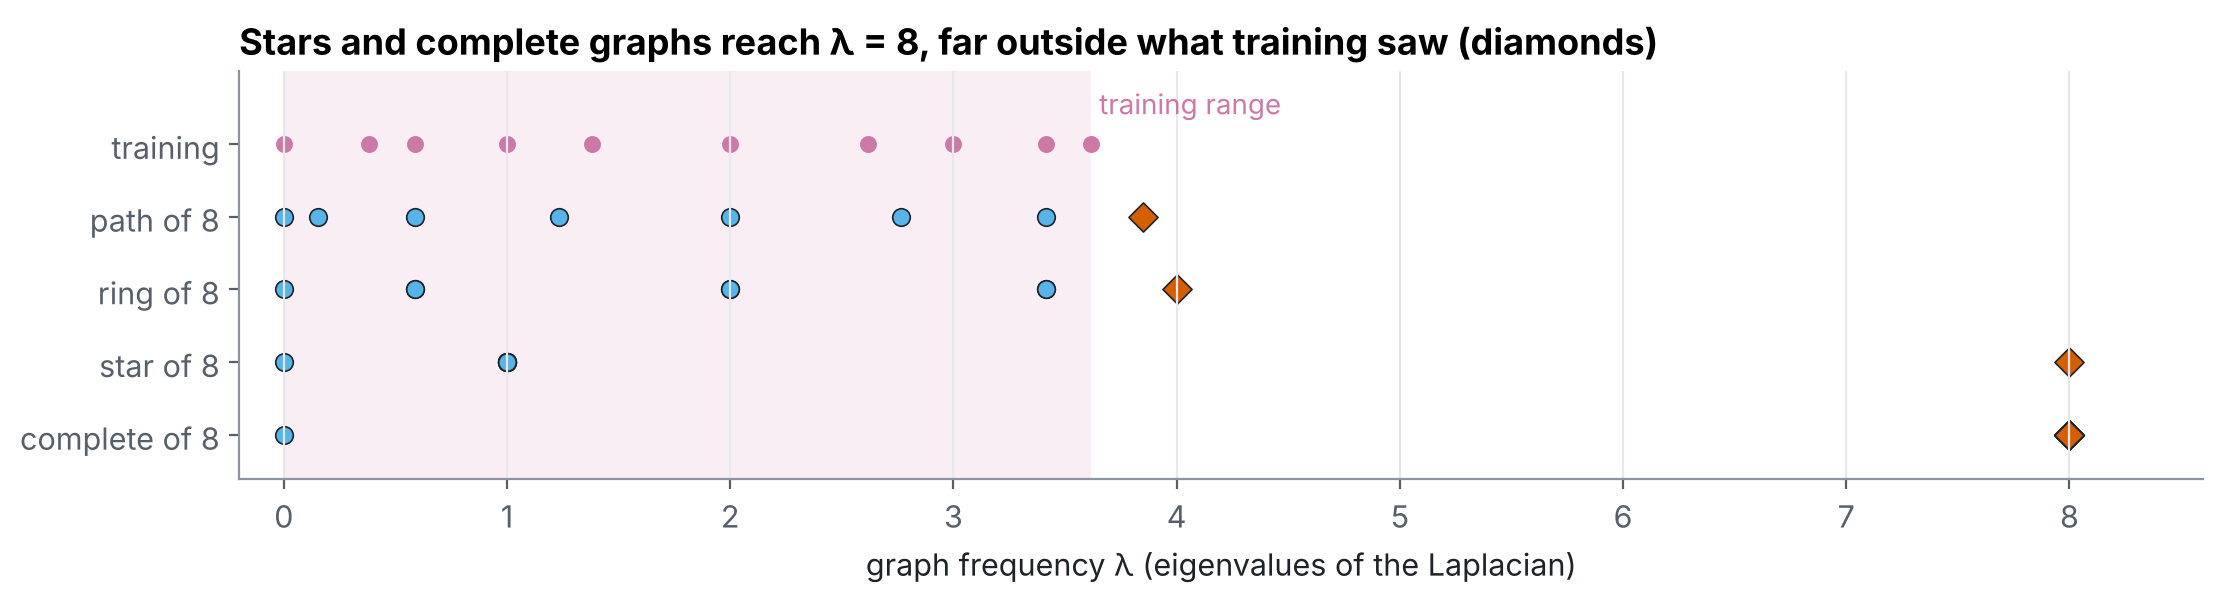

In [5]:
F.e2_graph_frequencies(runs[0]);

## Nominal vs actual, at κ = 4

Press **Play** to watch at real speed, or drag the slider. Actual bobs are filled, nominal bobs are hollow, and the whisker between them is the deviation, magnified (pick the factor) and coloured against the tolerance, like a CMM deviation plot. The trace underneath is the largest deviation over time. The ring stays inside the training frequencies; the star does not.

In [6]:
a = runs[0]["arrays"]
tol = 0.01 * p["amplitude"]
for nm, edges in (("ring", graphs.ring(8)), ("star", graphs.star(8))):
    display(viz.player(a[f"theta_act_k4_{nm}"], a[f"theta_nom_k4_{nm}"], edges, dt=world.dt, tol=tol,
                       title=f"{nm.capitalize()} of 8, κ = 4: transferred model (nominal) against the world (actual)",
                       subtitle="Fitted only on 3- and 5-body paths and rings. Tolerance: 1% of the swing."))

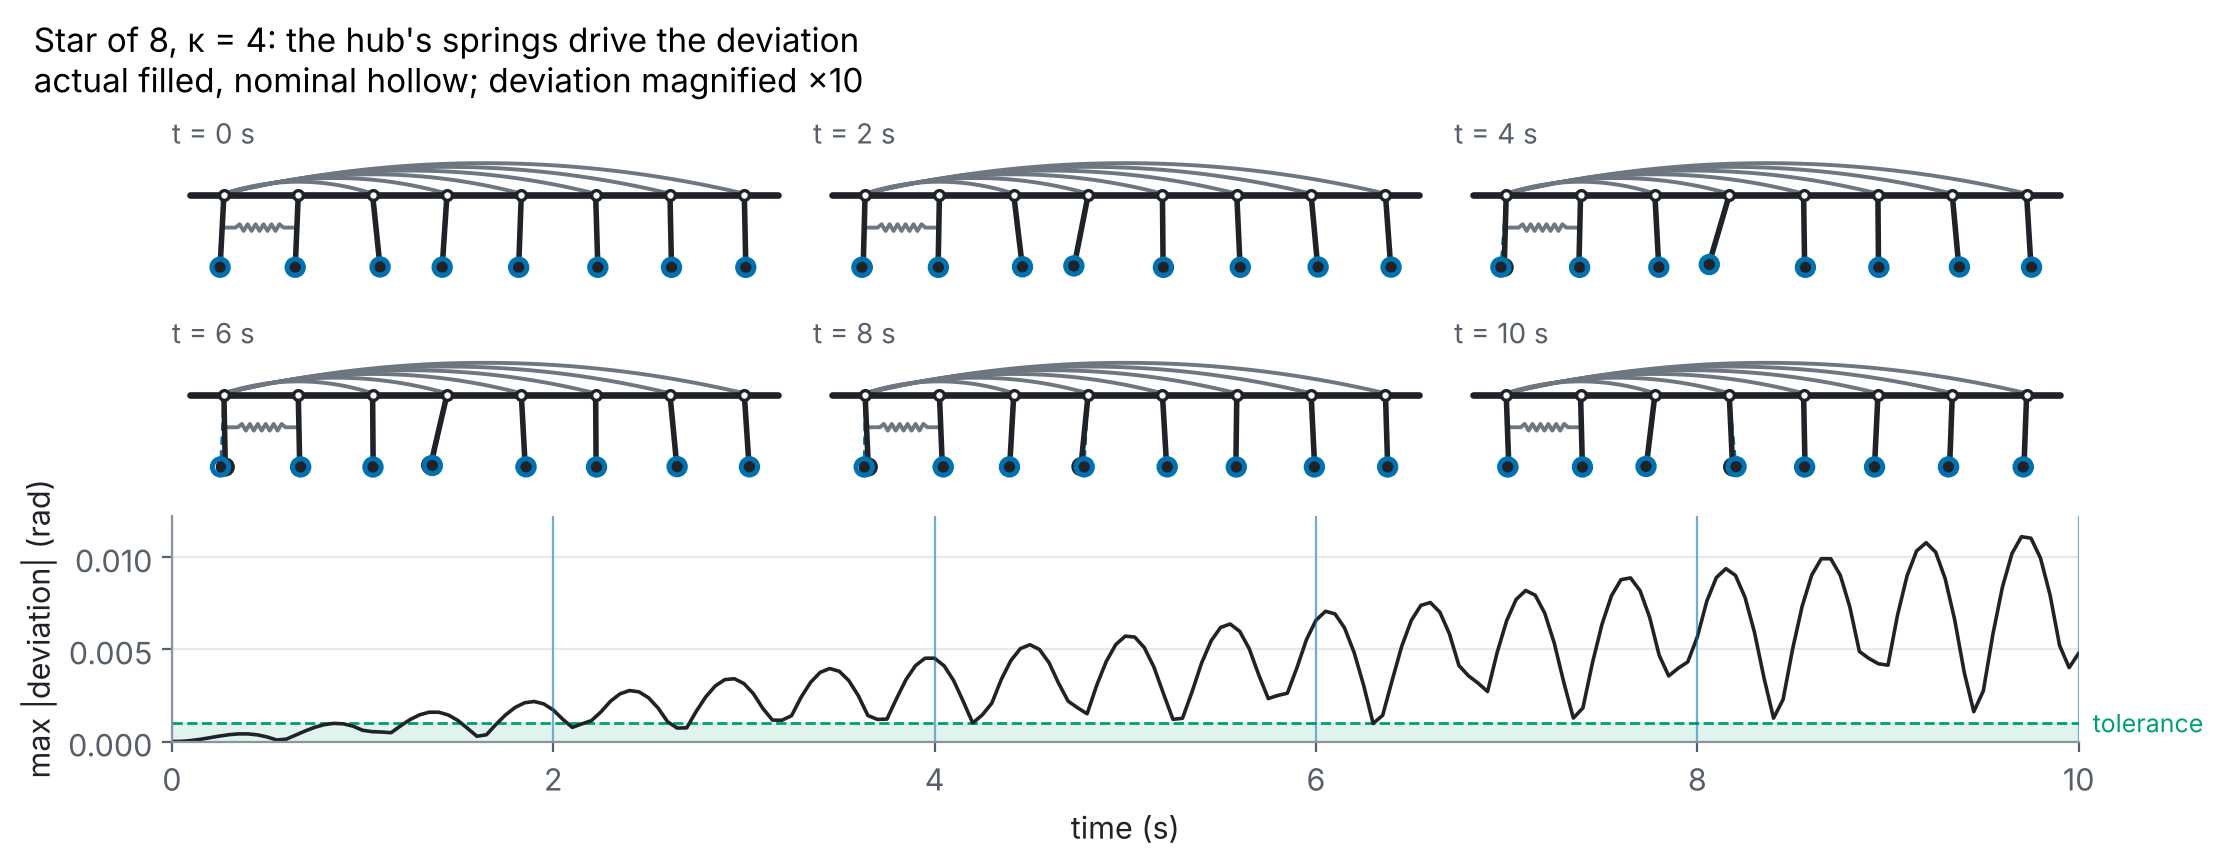

In [7]:
viz.film_strip(a["theta_act_k4_star"], a["theta_nom_k4_star"], graphs.star(8), dt=world.dt, tol=tol,
               title="Star of 8, κ = 4: the hub's springs drive the deviation");

## Where transfer holds

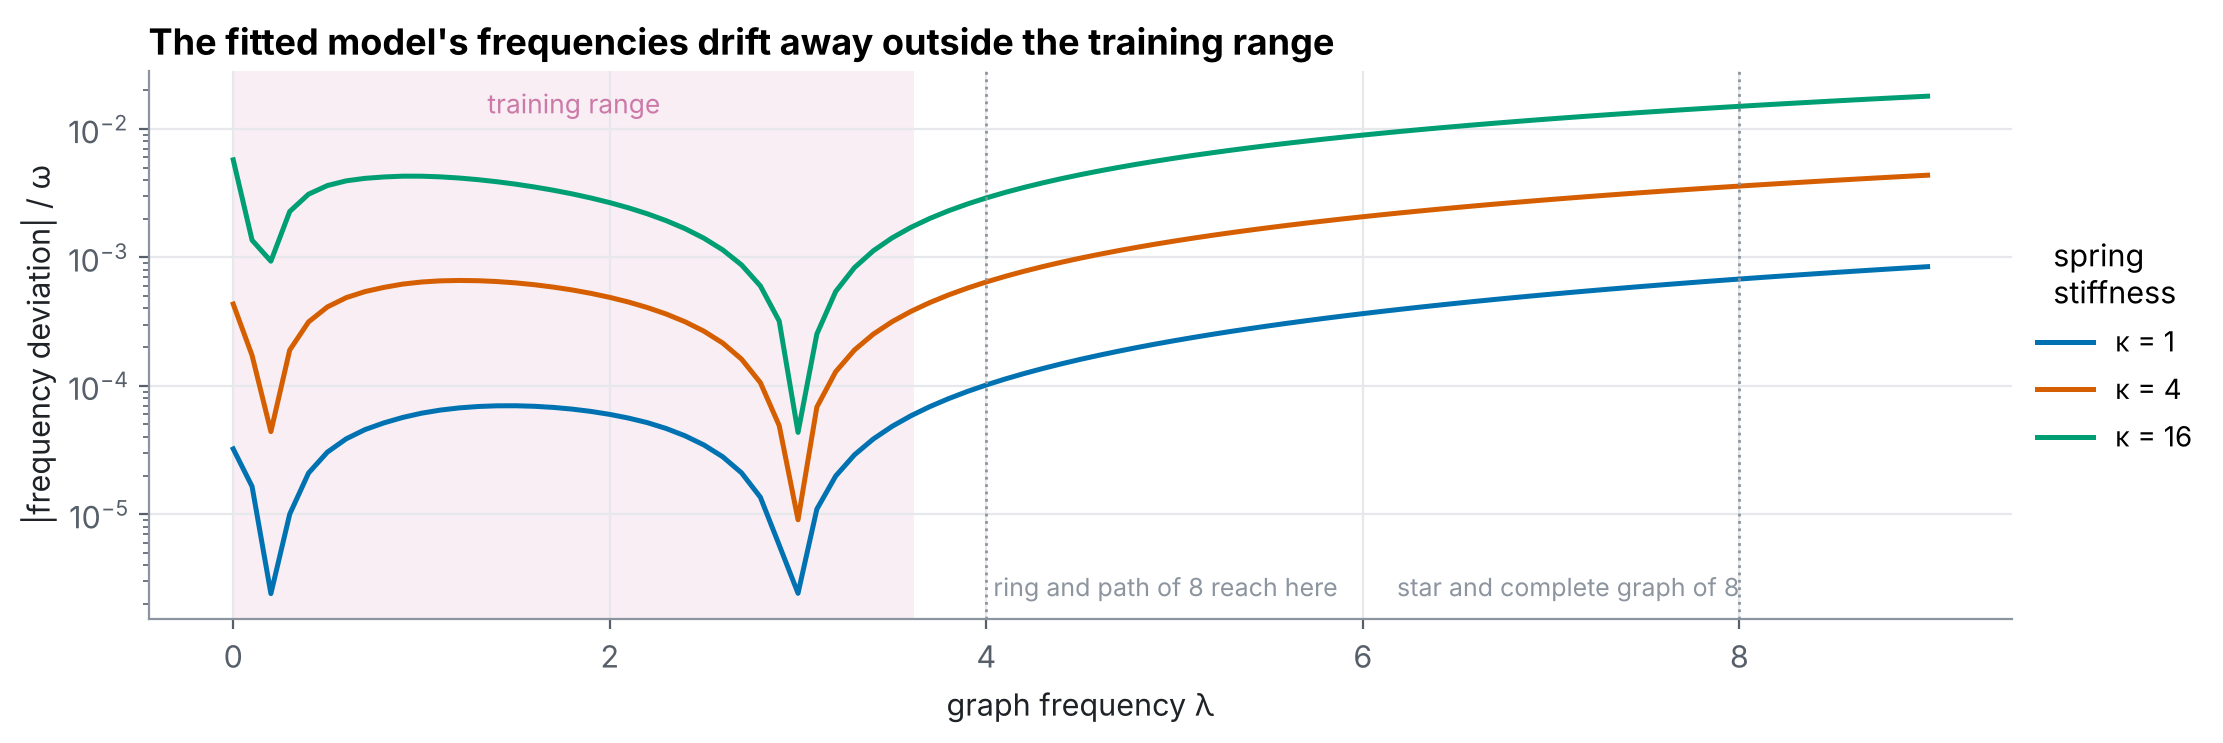

In [8]:
F.e2_frequency_error(runs);

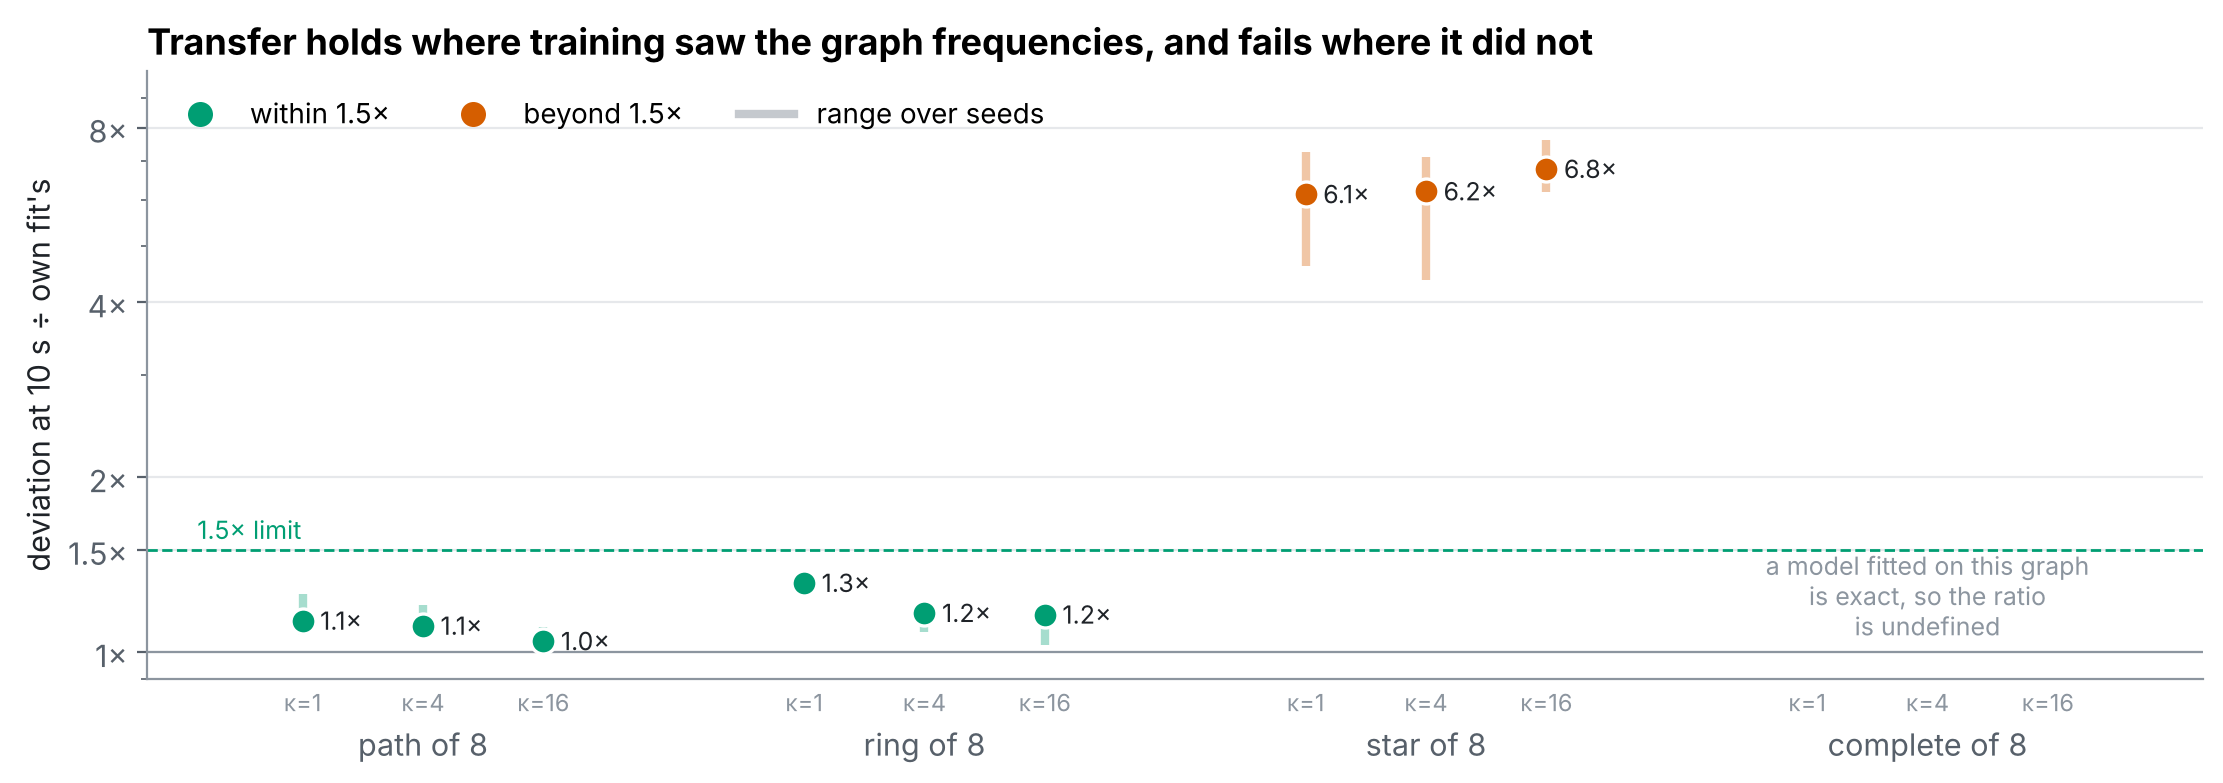

In [9]:
F.e2_ratios(runs);

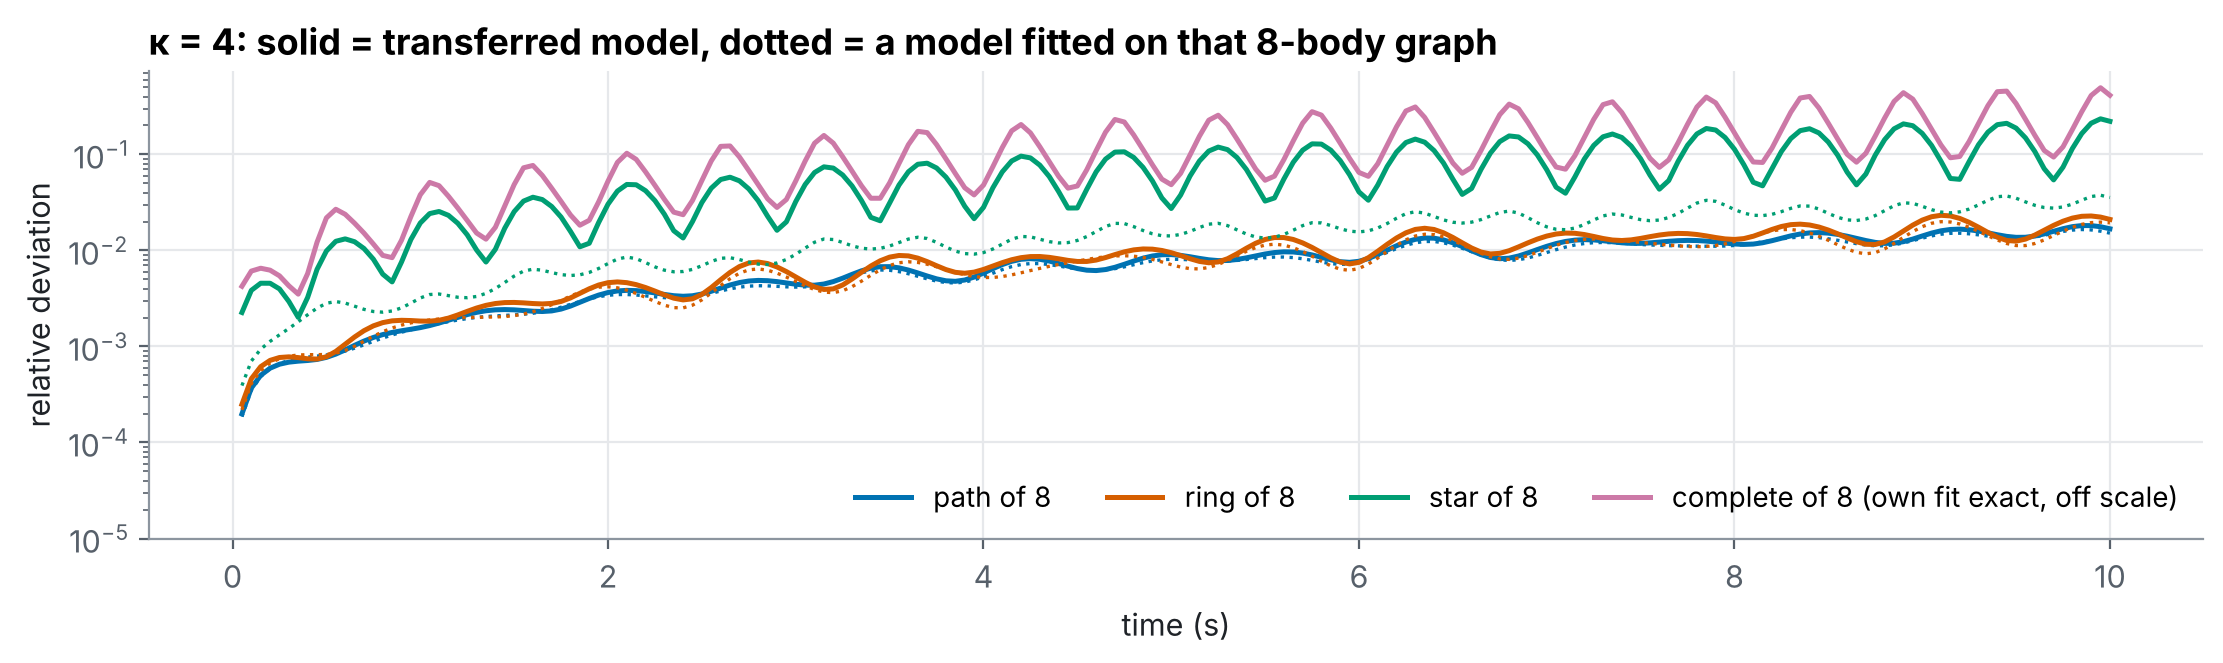

In [10]:
F.e2_rollouts(runs[0], 4.0, world);

In [11]:
g = lambda k, nm, key: [r["metrics"]["by_kappa"][k]["graphs"][nm][key] for r in runs]
ratio = lambda k, nm: [v for v in g(k, nm, "ratio") if not isinstance(v, str)]
F.say(f"Paths and rings of 8 transfer within {F.spread(ratio('1', 'path') + ratio('1', 'ring'))}× of their own fits at "
      f"κ = 1, and closer at stiffer springs. Stars land at {F.spread(ratio('1', 'star') + ratio('4', 'star') + ratio('16', 'star'))}× "
      "whatever the stiffness: the ratio tracks the graph frequencies, not the body count. A complete graph has only two "
      "graph frequencies (0 and 8), so a model fitted on it alone is exact; that is why its ratio is undefined.")

> **Finding.** Paths and rings of 8 transfer within 1.23 (1.07 to 1.33)× of their own fits at κ = 1, and closer at stiffer springs. Stars land at 6.26 (4.38 to 7.61)× whatever the stiffness: the ratio tracks the graph frequencies, not the body count. A complete graph has only two graph frequencies (0 and 8), so a model fitted on it alone is exact; that is why its ratio is undefined.

## Inspection report

In [12]:
rows = []
for k in ("1", "4", "16"):
    for nm in ("path", "ring", "star"):
        v = float(np.median(ratio(k, nm)))
        rows.append({"characteristic": f"{nm} of 8, κ = {k}: deviation at 10 s ÷ own fit's", "nominal": v,
                     "actual": 1.0, "deviation": v - 1, "tolerance": 0.5,
                     "status": viz.status(v - 1, 0.5) if nm != "star" else ("out" if v > 1.5 else "in")})
viz.inspection_report(rows, title="Transfer ratios (median over seeds); the plan's criterion covers paths and rings")

**Transfer ratios (median over seeds); the plan's criterion covers paths and rings**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| path of 8, κ = 1: deviation at 10 s ÷ own fit's | 1.133 | 1 | 0.1333 | ±0.5 | ✓ **in** |
| ring of 8, κ = 1: deviation at 10 s ÷ own fit's | 1.317 | 1 | 0.3166 | ±0.5 | ✓ **in** |
| star of 8, κ = 1: deviation at 10 s ÷ own fit's | 6.147 | 1 | 5.147 | ±0.5 | ✗ **out** |
| path of 8, κ = 4: deviation at 10 s ÷ own fit's | 1.111 | 1 | 0.1109 | ±0.5 | ✓ **in** |
| ring of 8, κ = 4: deviation at 10 s ÷ own fit's | 1.169 | 1 | 0.1686 | ±0.5 | ✓ **in** |
| star of 8, κ = 4: deviation at 10 s ÷ own fit's | 6.216 | 1 | 5.216 | ±0.5 | ✗ **out** |
| path of 8, κ = 16: deviation at 10 s ÷ own fit's | 1.045 | 1 | 0.04536 | ±0.5 | ✓ **in** |
| ring of 8, κ = 16: deviation at 10 s ÷ own fit's | 1.161 | 1 | 0.1611 | ±0.5 | ✓ **in** |
| star of 8, κ = 16: deviation at 10 s ÷ own fit's | 6.793 | 1 | 5.793 | ±0.5 | ✗ **out** |

## Log

In [13]:
F.log(runs)

| Seed | Code version | Run at (UTC) | Python | NumPy | SciPy |
| --- | --- | --- | --- | --- | --- |
| 0 | `fb79448` | 2026-11-25T20:28:50+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 1 | `fb79448` | 2026-11-25T20:28:51+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 2 | `fb79448` | 2026-11-25T20:28:52+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |